In [1]:
import scanpy as sc
import pandas as pd
import numpy as np

/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
adata = sc.read_10x_h5("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/morris/GSM6675628_B4D12-RNA-r2-1_filtered_feature_bc_matrix.h5")

/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [3]:
lineage_info_df = pd.read_csv('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/morris/b4.rna&atac.r1&2_master_rev1_annotated.csv')
lineage_info_df["barcode_stripped"] = [f[15:] for f in lineage_info_df["cell.bc"]] #for RNA delete first 16 characters
lineage_info_df = lineage_info_df.set_index("barcode_stripped")
# Keep only the first occurrence of each duplicate index
lineage_info_df = lineage_info_df.loc[~lineage_info_df.index.duplicated(keep='first')]
cells_with_lineage_info = lineage_info_df.index

In [4]:
cells_with_lineage_info_in_adata1 = [f for f in adata.obs_names if f in cells_with_lineage_info.values]
adata = adata[cells_with_lineage_info_in_adata1]
adata.obs["barcode"] = adata.obs_names.map(lineage_info_df["clone_id"])


/tmp/ipykernel_2773024/131653960.py:3: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs["barcode"] = adata.obs_names.map(lineage_info_df["clone_id"])
/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [5]:

# Mark MT genes
adata.var["mt"] = adata.var_names.str.upper().str.startswith("MT-")

# Compute MT % per cell
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], inplace=True)

# Filter cells with >3.5% MT
adata = adata[adata.obs["pct_counts_mt"] <= 3.5].copy()


/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [6]:
adata

AnnData object with n_obs × n_vars = 851 × 31056
    obs: 'barcode', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'

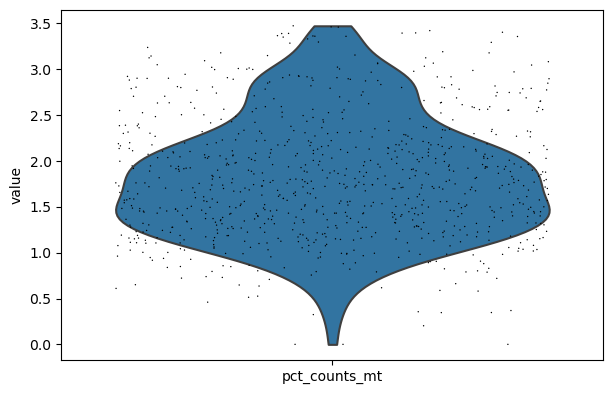

In [7]:
adata.var_names_make_unique()
sc.pl.violin(adata, 'pct_counts_mt', jitter=0.4)

In [8]:
sc.pp.filter_genes(adata, min_cells=2)
sc.pp.filter_cells(adata, min_genes=100)
sc.pp.normalize_total(adata , target_sum=1e4)
#sc.pp.log1p(adata)
df = pd.DataFrame(adata.X.todense(), columns = adata.var_names)
df["barcode"] = adata.obs["barcode"].values
df["barcode_cont"] = pd.factorize(df["barcode"])[0]
df = df.drop(columns = ["barcode"])

In [9]:
df

,Mrpl15,Lypla1,Tcea1,Rgs20,Atp6v1h,Rb1cc1,4732440D04Rik,Alkal1,Pcmtd1,Rrs1,...,mt-Cytb,Vamp7,Tmlhe,AC149090.1,CAAA01118383.1,CAAA01147332.1,CellTag.UTR,GFP.CDS,FoxA1.HNF4a,barcode_cont
0,4.169272,0.000000,2.084636,0.0,0.0,4.169272,0.0,0.0,2.084636,2.084636,...,31.269543,0.000000,0.0,0.000000,4.169272,0.0,18.761726,2.084636,0.000000,0
1,2.228164,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,0.000000,0.000000,...,33.422459,0.000000,0.0,0.000000,0.000000,0.0,40.106953,4.456328,0.000000,1
2,0.000000,0.000000,0.000000,0.0,0.0,2.055498,0.0,0.0,0.000000,0.000000,...,16.443987,0.000000,0.0,0.000000,2.055498,0.0,6.166495,2.055498,0.000000,2
3,0.000000,0.000000,0.000000,0.0,0.0,3.110904,0.0,0.0,1.555452,3.110904,...,18.665422,0.000000,0.0,1.555452,0.000000,0.0,40.441750,3.110904,1.555452,3
4,0.000000,2.016536,0.000000,0.0,0.0,6.049606,0.0,0.0,0.000000,0.000000,...,14.115748,0.000000,0.0,0.000000,4.033071,0.0,22.181890,0.000000,0.000000,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
846,3.732736,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,0.000000,0.000000,...,33.594627,0.000000,0.0,0.000000,0.000000,0.0,14.930945,3.732736,0.000000,151
847,3.640335,1.820168,0.000000,0.0,0.0,3.640335,0.0,0.0,0.000000,1.820168,...,25.482346,0.000000,0.0,1.820168,0.000000,0.0,1.820168,1.820168,5.460503,335
848,0.000000,0.000000,1.812908,0.0,0.0,0.000000,0.0,0.0,0.000000,0.000000,...,38.071068,0.000000,0.0,0.000000,0.000000,0.0,29.006527,3.625816,0.000000,426
849,0.000000,0.000000,0.000000,0.0,0.0,1.658925,0.0,0.0,0.000000,0.000000,...,28.201723,0.000000,0.0,0.000000,0.000000,0.0,34.837425,1.658925,0.000000,98


In [11]:
df.to_pickle("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered_nolog/morris_RNA_nolog.pkl"
            
            )